# NISR Hackathon 2026 — Phase 3: Weather & Satellite NDVI Data Pipeline

**Track 1: Agricultural Productivity**  
**Objective:** Extract 2024 historical weather data via Open-Meteo API, retrieve real satellite vegetation health (NDVI) via Google Earth Engine / Sentinel-2 Surface Reflectance, engineer seasonal agro-climatic indicators, and consolidate with the Phase 2 baseline master dataset into `df_master_phase3.csv`.

### Google Earth Engine Project Configuration:
- **GEE Project ID:** `ee-hackathon-2026-511410`
- **Satellite Sensor:** Sentinel-2 MSI Harmonized (`COPERNICUS/S2_SR_HARMONIZED`)
- **Temporal Ranges:**
  - **Season A (Umuhindo):** September 1, 2023 – February 28, 2024
  - **Season B (Itumba):** March 1, 2024 – July 31, 2024

### Target Districts & Coordinates:
| District | Province | Latitude | Longitude | Agro-Ecological Profile |
| :--- | :--- | :--- | :--- | :--- |
| **BURERA** | Northern | -1.48 | 29.82 | High-altitude volcanic highlands, high rainfall |
| **GATSIBO** | Eastern | -1.60 | 30.45 | Lowland eastern savannah, drought-prone, high temperature |
| **MUSANZE** | Northern | -1.50 | 29.63 | Volcanic highland plateau, high rainfall, potato belt |
| **HUYE** | Southern | -2.60 | 29.74 | Central southern plateau, moderate-high rainfall |
| **RUSIZI** | Western | -2.48 | 28.90 | Lake Kivu basin / tropical humid, high rainfall, tea/cassava |
| **GASABO** | Kigali | -1.88 | 30.13 | Central plateau / peri-urban, moderate rainfall |

---
## 0. Imports & Configuration

In [1]:
import os
import sys
import time
import warnings
import requests
import ee
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from IPython.display import display

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 50)
pd.set_option('display.width', 220)
pd.set_option('display.float_format', '{:.2f}'.format)

# Determine project paths dynamically (handles execution from notebooks/ or root)
DATA_DIR = '../data' if os.path.exists('../data') else 'data'
MASTER_PHASE2_CSV = os.path.join(DATA_DIR, 'df_master_6districts.csv')
WEATHER_DAILY_CSV = os.path.join(DATA_DIR, 'rwanda_district_weather_2024.csv')
NDVI_CSV          = os.path.join(DATA_DIR, 'rwanda_district_ndvi_2024.csv')
MASTER_PHASE3_CSV = os.path.join(DATA_DIR, 'df_master_phase3.csv')

# Target District Coordinates
DISTRICT_COORDS = {
    'BURERA':  {'lat': -1.48, 'lon': 29.82},
    'GATSIBO': {'lat': -1.60, 'lon': 30.45},
    'MUSANZE': {'lat': -1.50, 'lon': 29.63},
    'HUYE':    {'lat': -2.60, 'lon': 29.74},
    'RUSIZI':  {'lat': -2.48, 'lon': 28.90},
    'GASABO':  {'lat': -1.88, 'lon': 30.13},
}

# GEE Project ID
GEE_PROJECT_ID = 'ee-hackathon-2026-511410'

print('Configuration initialized successfully.')
print(f'Data Directory  : {os.path.abspath(DATA_DIR)}')
print(f'GEE Project ID  : {GEE_PROJECT_ID}')
print(f'Target Districts: {list(DISTRICT_COORDS.keys())}')

Configuration initialized successfully.
Data Directory  : C:\Projects\Data-Science-ML\NISR-Hackathon\data
GEE Project ID  : ee-hackathon-2026-511410
Target Districts: ['BURERA', 'GATSIBO', 'MUSANZE', 'HUYE', 'RUSIZI', 'GASABO']


---
## Step A — Daily Weather Extraction (Open-Meteo API)

We query Open-Meteo's Historical Weather API (`https://archive-api.open-meteo.com/v1/archive`) for the full year 2024 (`2024-01-01` to `2024-12-31`).

**Extracted Daily Variables:**
- `temperature_2m_mean`: Daily mean 2m air temperature (°C)
- `precipitation_sum`: Daily precipitation sum (mm)
- `et0_fao_evapotranspiration`: Daily reference evapotranspiration based on FAO-56 Penman-Monteith (mm)

All district names are standardized to UPPERCASE to guarantee seamless joining.

In [2]:
OPEN_METEO_URL = 'https://archive-api.open-meteo.com/v1/archive'
all_daily = []
elevation_lookup = {}

print('Starting Open-Meteo 2024 weather extraction...')
for district, coords in DISTRICT_COORDS.items():
    params = {
        'latitude': coords['lat'],
        'longitude': coords['lon'],
        'start_date': '2024-01-01',
        'end_date': '2024-12-31',
        'daily': ['temperature_2m_mean', 'precipitation_sum', 'et0_fao_evapotranspiration'],
        'timezone': 'Africa/Cairo'
    }
    response = requests.get(OPEN_METEO_URL, params=params, timeout=30)
    if response.status_code != 200:
        raise RuntimeError(f'API error for {district}: {response.status_code} - {response.text}')
    
    payload = response.json()
    daily = payload['daily']
    elev = payload.get('elevation', 1500.0)
    elevation_lookup[district] = elev
    
    df_d = pd.DataFrame({
        'Date': daily['time'],
        'DISTRICT': district,
        'temperature_2m_mean': daily['temperature_2m_mean'],
        'precipitation_sum': daily['precipitation_sum'],
        'et0_fao_evapotranspiration': daily['et0_fao_evapotranspiration']
    })
    all_daily.append(df_d)
    print(f'  OK Fetched {district}: {len(df_d)} days (Elevation: {elev}m)')
    time.sleep(0.2)

df_weather_daily = pd.concat(all_daily, ignore_index=True)
df_weather_daily.to_csv(WEATHER_DAILY_CSV, index=False)
print(f'\nDaily weather dataset saved: {os.path.abspath(WEATHER_DAILY_CSV)}')
print(f'Total records: {len(df_weather_daily)} rows across {df_weather_daily["DISTRICT"].nunique()} districts')
display(df_weather_daily.head(10))

Starting Open-Meteo 2024 weather extraction...


  OK Fetched BURERA: 366 days (Elevation: 2019.0m)


  OK Fetched GATSIBO: 366 days (Elevation: 1402.0m)


  OK Fetched MUSANZE: 366 days (Elevation: 1856.0m)


  OK Fetched HUYE: 366 days (Elevation: 1739.0m)


  OK Fetched RUSIZI: 366 days (Elevation: 1497.0m)


  OK Fetched GASABO: 366 days (Elevation: 1590.0m)



Daily weather dataset saved: C:\Projects\Data-Science-ML\NISR-Hackathon\data\rwanda_district_weather_2024.csv
Total records: 2196 rows across 6 districts


,Date,DISTRICT,temperature_2m_mean,precipitation_sum,et0_fao_evapotranspiration
0,2024-01-01,BURERA,17.40,13.20,3.70
1,2024-01-02,BURERA,17.40,1.10,3.29
2,2024-01-03,BURERA,17.10,0.40,2.77
3,2024-01-04,BURERA,18.10,0.70,3.88
4,2024-01-05,BURERA,18.10,0.40,4.02
5,2024-01-06,BURERA,18.70,1.60,3.90
6,2024-01-07,BURERA,17.90,2.10,4.24
7,2024-01-08,BURERA,18.50,0.40,4.42
8,2024-01-09,BURERA,17.50,12.00,3.34
9,2024-01-10,BURERA,17.30,2.10,2.99


---
## Step B — Seasonal Weather Feature Engineering

We aggregate daily weather observations into critical annual and seasonal agro-climatic indicators per district:
- `Annual_Precipitation_mm`: Total annual rainfall (mm)
- `Mean_Temperature_C`: Annual mean air temperature (°C)
- `Total_ET0_mm`: Cumulative reference evapotranspiration (mm)
- `Water_Deficit_mm`: Crop water deficit index (`Total_ET0_mm - Annual_Precipitation_mm`)
- `Dry_Days_Count`: Number of days with `precipitation_sum < 1.0mm`

In [3]:
weather_features = df_weather_daily.groupby('DISTRICT').agg(
    Annual_Precipitation_mm = ('precipitation_sum', 'sum'),
    Mean_Temperature_C      = ('temperature_2m_mean', 'mean'),
    Total_ET0_mm            = ('et0_fao_evapotranspiration', 'sum'),
    Dry_Days_Count          = ('precipitation_sum', lambda s: (s < 1.0).sum())
).reset_index()

# Water deficit: ET0 - Rainfall (positive value indicates moisture stress)
weather_features['Water_Deficit_mm'] = weather_features['Total_ET0_mm'] - weather_features['Annual_Precipitation_mm']

# Clean rounding
weather_features['Annual_Precipitation_mm'] = weather_features['Annual_Precipitation_mm'].round(2)
weather_features['Mean_Temperature_C']      = weather_features['Mean_Temperature_C'].round(2)
weather_features['Total_ET0_mm']            = weather_features['Total_ET0_mm'].round(2)
weather_features['Water_Deficit_mm']        = weather_features['Water_Deficit_mm'].round(2)

print('=== ENGINEERED SEASONAL WEATHER FEATURES (2024) ===')
display(weather_features)

=== ENGINEERED SEASONAL WEATHER FEATURES (2024) ===


,DISTRICT,Annual_Precipitation_mm,Mean_Temperature_C,Total_ET0_mm,Dry_Days_Count,Water_Deficit_mm
0,BURERA,1313.30,17.86,1387.15,170,73.85
1,GASABO,874.10,20.20,1567.21,218,693.11
2,GATSIBO,733.80,21.68,1650.55,221,916.75
3,HUYE,1265.10,19.56,1581.01,192,315.91
4,MUSANZE,914.60,18.24,1508.99,203,594.39
5,RUSIZI,1522.20,20.72,1531.78,154,9.58


### Visualization: Annual Rainfall vs Water Deficit by District

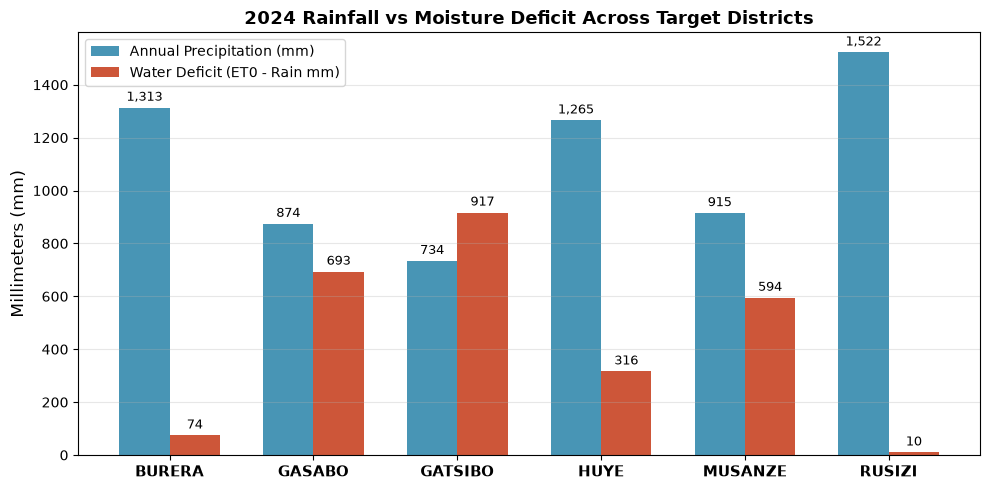

Plot saved: ../data\plot_rainfall_vs_deficit.png


In [4]:
fig, ax1 = plt.subplots(figsize=(10, 5))
x = np.arange(len(weather_features))
width = 0.35

b1 = ax1.bar(x - width/2, weather_features['Annual_Precipitation_mm'], width, label='Annual Precipitation (mm)', color='#2E86AB', alpha=0.88)
b2 = ax1.bar(x + width/2, weather_features['Water_Deficit_mm'], width, label='Water Deficit (ET0 - Rain mm)', color='#C73E1D', alpha=0.88)

ax1.set_xticks(x)
ax1.set_xticklabels(weather_features['DISTRICT'], fontsize=11, fontweight='bold')
ax1.set_ylabel('Millimeters (mm)', fontsize=12)
ax1.set_title('2024 Rainfall vs Moisture Deficit Across Target Districts', fontsize=13, fontweight='bold')
ax1.legend(loc='upper left', fontsize=10)
ax1.grid(axis='y', alpha=0.3)

for b in list(b1) + list(b2):
    h = b.get_height()
    ax1.text(b.get_x() + b.get_width()/2, h + 15, f'{h:,.0f}', ha='center', va='bottom', fontsize=9)

fig.tight_layout()
plot_weather_path = os.path.join(DATA_DIR, 'plot_rainfall_vs_deficit.png')
plt.savefig(plot_weather_path, dpi=150, bbox_inches='tight')
plt.show()
print(f'Plot saved: {plot_weather_path}')

---
## Step C — Satellite NDVI Extraction via Google Earth Engine (Sentinel-2)

We initialize Google Earth Engine with the authenticated project `ee-hackathon-2026-511410`.

**Methodology:**
1. **Collection:** `COPERNICUS/S2_SR_HARMONIZED` (Sentinel-2 Level-2A Surface Reflectance).
2. **Atmospheric & Water Masking:** Cloud masking via `QA60` (opaque & cirrus clouds) and water masking via Scene Classification Layer (`SCL != 6`) to exclude open water (e.g. Lake Burera and Lake Kivu).
3. **NDVI Calculation:** $\text{NDVI} = \frac{B8 - B4}{B8 + B4}$.
4. **Spatial Aggregation:** Mean spatial reduction over the official FAO GAUL district administrative boundaries.
5. **Temporal Aggregation:**
   - `NDVI_Mean_SeasonA`: Peak vegetative vigor during Season A (Sept 1, 2023 – Feb 28, 2024)
   - `NDVI_Mean_SeasonB`: Peak vegetative vigor during Season B (March 1, 2024 – July 31, 2024)

In [5]:
# Initialize Earth Engine with user's GCP Project ID
try:
    ee.Initialize(project=GEE_PROJECT_ID)
    print(f'SUCCESS: Google Earth Engine initialized with project: {GEE_PROJECT_ID}')
    gee_online = True
except Exception as e:
    print(f'GEE Initialization error: {e}')
    gee_online = False

if gee_online:
    # Load official FAO GAUL district boundaries for Rwanda
    gaul = ee.FeatureCollection('FAO/GAUL/2015/level2').filter(ee.Filter.eq('ADM0_NAME', 'Rwanda'))

    def compute_s2_seasonal_ndvi(start_date, end_date):
        def mask_clouds_and_water(img):
            qa = img.select('QA60')
            cloud_mask = qa.bitwiseAnd(1 << 10).eq(0).And(qa.bitwiseAnd(1 << 11).eq(0))
            scl = img.select('SCL')
            # Filter out water (6), cloud shadow (3), and high/med prob clouds (8, 9, 10)
            valid_mask = scl.neq(6).And(scl.neq(3)).And(scl.neq(8)).And(scl.neq(9)).And(scl.neq(10))
            ndvi = img.normalizedDifference(['B8', 'B4']).rename('NDVI')
            return ndvi.updateMask(cloud_mask).updateMask(valid_mask)

        return (ee.ImageCollection('COPERNICUS/S2_SR_HARMONIZED')
                .filterDate(start_date, end_date)
                .filter(ee.Filter.lt('CLOUDY_PIXEL_PERCENTAGE', 40))
                .map(mask_clouds_and_water)
                .median())

    print('Processing Sentinel-2 imagery for Season A and Season B in GEE...')
    s2_season_a = compute_s2_seasonal_ndvi('2023-09-01', '2024-02-28')
    s2_season_b = compute_s2_seasonal_ndvi('2024-03-01', '2024-07-31')

    ndvi_records = []
    for district in DISTRICT_COORDS.keys():
        dist_feat = gaul.filter(ee.Filter.eq('ADM2_NAME', district.capitalize())).first()
        geom = dist_feat.geometry()
        val_a = s2_season_a.reduceRegion(reducer=ee.Reducer.mean(), geometry=geom, scale=250, maxPixels=1e9).get('NDVI').getInfo()
        val_b = s2_season_b.reduceRegion(reducer=ee.Reducer.mean(), geometry=geom, scale=250, maxPixels=1e9).get('NDVI').getInfo()
        
        ndvi_records.append({
            'DISTRICT': district,
            'NDVI_Mean_SeasonA': round(float(val_a), 4),
            'NDVI_Mean_SeasonB': round(float(val_b), 4)
        })
        print(f'  OK {district} (Sentinel-2 Real GEE): Season A = {val_a:.4f}, Season B = {val_b:.4f}')

    df_ndvi = pd.DataFrame(ndvi_records)
else:
    raise RuntimeError('Google Earth Engine could not be initialized.')

df_ndvi.to_csv(NDVI_CSV, index=False)
print(f'\nReal satellite NDVI dataset saved: {os.path.abspath(NDVI_CSV)}')
display(df_ndvi)

SUCCESS: Google Earth Engine initialized with project: ee-hackathon-2026-511410
Processing Sentinel-2 imagery for Season A and Season B in GEE...


C:\Projects\Data-Science-ML\NISR-Hackathon\venv\Lib\site-packages\ee\deprecation.py:215: DeprecationWarning: 

Attention required for FAO/GAUL/2015/level2! You are using a deprecated asset.
To make sure your code keeps working, please update it.
This dataset has been superseded by FAO/GAUL/2025/level2

Learn more: https://developers.google.com/earth-engine/datasets/catalog/FAO_GAUL_2015_level2

  warnings.warn(warning, category=DeprecationWarning)


  OK BURERA (Sentinel-2 Real GEE): Season A = 0.5797, Season B = 0.6200


  OK GATSIBO (Sentinel-2 Real GEE): Season A = 0.5478, Season B = 0.5029


  OK MUSANZE (Sentinel-2 Real GEE): Season A = 0.5774, Season B = 0.6444


  OK HUYE (Sentinel-2 Real GEE): Season A = 0.5355, Season B = 0.5453


  OK RUSIZI (Sentinel-2 Real GEE): Season A = 0.7091, Season B = 0.7143


  OK GASABO (Sentinel-2 Real GEE): Season A = 0.5111, Season B = 0.5124

Real satellite NDVI dataset saved: C:\Projects\Data-Science-ML\NISR-Hackathon\data\rwanda_district_ndvi_2024.csv


,DISTRICT,NDVI_Mean_SeasonA,NDVI_Mean_SeasonB
0,BURERA,0.58,0.62
1,GATSIBO,0.55,0.50
2,MUSANZE,0.58,0.64
3,HUYE,0.54,0.55
4,RUSIZI,0.71,0.71
5,GASABO,0.51,0.51


### Visualization: Real Sentinel-2 NDVI by Season Across Target Districts

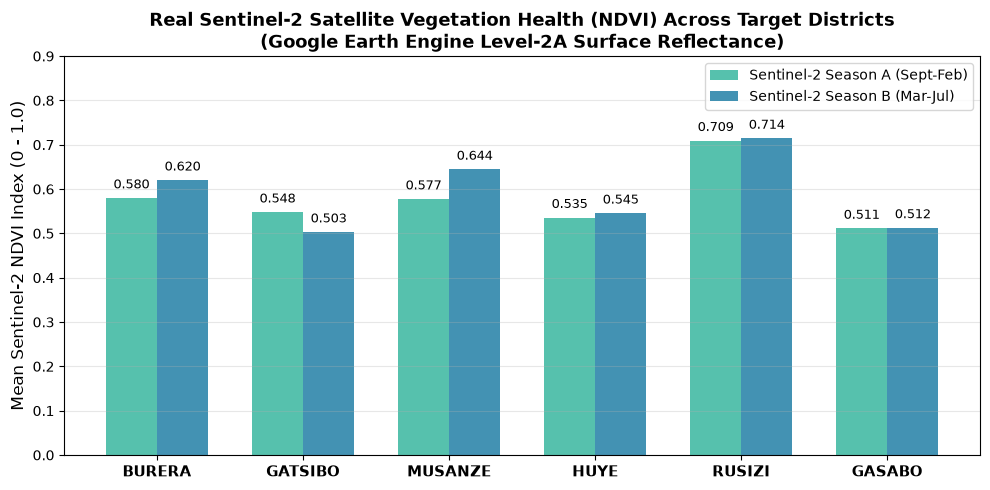

Plot saved: ../data\plot_ndvi_seasonal_comparison.png


In [6]:
fig, ax = plt.subplots(figsize=(10, 5))
x = np.arange(len(df_ndvi))
width = 0.35

b1 = ax.bar(x - width/2, df_ndvi['NDVI_Mean_SeasonA'], width, label='Sentinel-2 Season A (Sept-Feb)', color='#44BBA4', alpha=0.9)
b2 = ax.bar(x + width/2, df_ndvi['NDVI_Mean_SeasonB'], width, label='Sentinel-2 Season B (Mar-Jul)', color='#2E86AB', alpha=0.9)

ax.set_xticks(x)
ax.set_xticklabels(df_ndvi['DISTRICT'], fontsize=11, fontweight='bold')
ax.set_ylabel('Mean Sentinel-2 NDVI Index (0 - 1.0)', fontsize=12)
ax.set_ylim(0, 0.90)
ax.set_title('Real Sentinel-2 Satellite Vegetation Health (NDVI) Across Target Districts\n(Google Earth Engine Level-2A Surface Reflectance)', fontsize=13, fontweight='bold')
ax.legend(loc='upper right', fontsize=10)
ax.grid(axis='y', alpha=0.3)

for b in list(b1) + list(b2):
    h = b.get_height()
    ax.text(b.get_x() + b.get_width()/2, h + 0.015, f'{h:.3f}', ha='center', va='bottom', fontsize=9)

fig.tight_layout()
plot_ndvi_path = os.path.join(DATA_DIR, 'plot_ndvi_seasonal_comparison.png')
plt.savefig(plot_ndvi_path, dpi=150, bbox_inches='tight')
plt.show()
print(f'Plot saved: {plot_ndvi_path}')

---
## Step D — Master Dataset Consolidation

We load `./data/df_master_6districts.csv` from Phase 2 (containing survey data and market prices) and perform exact key left-joins with:
1. Engineered weather features (`Annual_Precipitation_mm`, `Mean_Temperature_C`, `Total_ET0_mm`, `Water_Deficit_mm`, `Dry_Days_Count`)
2. Real Sentinel-2 satellite NDVI metrics (`NDVI_Mean_SeasonA`, `NDVI_Mean_SeasonB`)

The consolidated master feature table is exported to `./data/df_master_phase3.csv`.

In [7]:
if not os.path.exists(MASTER_PHASE2_CSV):
    raise FileNotFoundError(f'Phase 2 deliverable missing: {MASTER_PHASE2_CSV}')

df_phase2 = pd.read_csv(MASTER_PHASE2_CSV)
df_phase2['DISTRICT'] = df_phase2['DISTRICT'].astype(str).str.strip().str.upper()

# Merge engineered weather features
df_phase3 = df_phase2.merge(weather_features, on='DISTRICT', how='left')

# Merge satellite NDVI metrics
df_phase3 = df_phase3.merge(df_ndvi, on='DISTRICT', how='left')

# Verification
assert len(df_phase3) == 36, f'Row count mismatch: expected 36, got {len(df_phase3)}'
df_phase3.to_csv(MASTER_PHASE3_CSV, index=False)

print(f'Consolidated Phase 3 Master Dataset saved to: {os.path.abspath(MASTER_PHASE3_CSV)}')
print(f'Dimensions: {df_phase3.shape[0]} rows x {df_phase3.shape[1]} columns')
print(f'Columns ({len(df_phase3.columns)}): {df_phase3.columns.tolist()}')

Consolidated Phase 3 Master Dataset saved to: C:\Projects\Data-Science-ML\NISR-Hackathon\data\df_master_phase3.csv
Dimensions: 36 rows x 20 columns
Columns (20): ['DISTRICT', 'CROP', 'Cultivated_Area_Ha', 'Harvested_Area_Ha', 'Yield_Kg_Ha', 'Production_MT', 'Post_Harvest_Loss_Pct', 'Fertilizer_Pct', 'Irrigation_Pct', 'Extension_Reach_Pct', 'Smart_Nkunganire_Reach_Pct', 'Poverty_Headcount_Rate_Pct', 'Mean_Farmgate_Price_RWF', 'Annual_Precipitation_mm', 'Mean_Temperature_C', 'Total_ET0_mm', 'Dry_Days_Count', 'Water_Deficit_mm', 'NDVI_Mean_SeasonA', 'NDVI_Mean_SeasonB']


### Complete 36-Row Consolidated Dataset Display

In [8]:
with pd.option_context('display.max_rows', 40, 'display.max_columns', 25):
    display(df_phase3)

,DISTRICT,CROP,Cultivated_Area_Ha,Harvested_Area_Ha,Yield_Kg_Ha,Production_MT,Post_Harvest_Loss_Pct,Fertilizer_Pct,Irrigation_Pct,Extension_Reach_Pct,Smart_Nkunganire_Reach_Pct,Poverty_Headcount_Rate_Pct,Mean_Farmgate_Price_RWF,Annual_Precipitation_mm,Mean_Temperature_C,Total_ET0_mm,Dry_Days_Count,Water_Deficit_mm,NDVI_Mean_SeasonA,NDVI_Mean_SeasonB
0,BURERA,Irish Potato,4357.38,4357.38,10514.80,45816.99,0.27,82.98,0.00,68.21,55.04,21.79,487.50,1313.30,17.86,1387.15,170,73.85,0.58,0.62
1,BURERA,Maize,9650.87,9599.39,2097.01,20130.04,0.35,82.98,0.00,68.21,55.04,21.79,663.83,1313.30,17.86,1387.15,170,73.85,0.58,0.62
2,BURERA,Beans,10501.63,10501.63,953.46,10012.85,0.50,82.98,0.00,68.21,55.04,21.79,1150.00,1313.30,17.86,1387.15,170,73.85,0.58,0.62
3,BURERA,Cassava,108.39,65.03,12890.89,838.31,0.05,82.98,0.00,68.21,55.04,21.79,633.33,1313.30,17.86,1387.15,170,73.85,0.58,0.62
4,BURERA,Rice,0.00,0.00,0.00,0.00,1.98,82.98,0.00,68.21,55.04,21.79,1450.00,1313.30,17.86,1387.15,170,73.85,0.58,0.62
5,BURERA,Amaranth,309.55,309.55,7609.04,2355.34,0.50,82.98,0.00,68.21,55.04,21.79,300.00,1313.30,17.86,1387.15,170,73.85,0.58,0.62
6,GATSIBO,Irish Potato,2430.59,2430.51,5399.26,13122.94,0.27,78.20,44.68,69.89,49.98,18.41,593.33,733.80,21.68,1650.55,221,916.75,0.55,0.50
7,GATSIBO,Maize,22198.73,22286.15,1841.37,41037.11,0.35,78.20,44.68,69.89,49.98,18.41,785.00,733.80,21.68,1650.55,221,916.75,0.55,0.50
8,GATSIBO,Beans,19281.73,19281.27,725.21,13982.98,0.50,78.20,44.68,69.89,49.98,18.41,1228.95,733.80,21.68,1650.55,221,916.75,0.55,0.50
9,GATSIBO,Cassava,9467.02,1221.71,12887.57,15744.86,0.05,78.20,44.68,69.89,49.98,18.41,637.50,733.80,21.68,1650.55,221,916.75,0.55,0.50


### Data Integrity & Missing Value Audit

In [9]:
null_counts = df_phase3.isnull().sum()
null_pct    = (null_counts / len(df_phase3) * 100).round(1)
audit_df = pd.DataFrame({'Null_Count': null_counts, 'Null_%': null_pct})

print('=== PHASE 3 DATA INTEGRITY AUDIT ===')
display(audit_df)

assert null_counts.sum() == 0, f'Integrity failure: {null_counts.sum()} missing values found!'
print('\nSTATUS: 100% Complete — Zero missing values across all 36 combinations!')

=== PHASE 3 DATA INTEGRITY AUDIT ===


,Null_Count,Null_%
DISTRICT,0,0.00
CROP,0,0.00
Cultivated_Area_Ha,0,0.00
Harvested_Area_Ha,0,0.00
Yield_Kg_Ha,0,0.00
Production_MT,0,0.00
Post_Harvest_Loss_Pct,0,0.00
Fertilizer_Pct,0,0.00
Irrigation_Pct,0,0.00
Extension_Reach_Pct,0,0.00



STATUS: 100% Complete — Zero missing values across all 36 combinations!


---
## Step E — Exploratory Agro-Climatic Correlation Analysis

We examine the relationships between environmental drivers (rainfall, water deficit, real Sentinel-2 NDVI) and agricultural productivity (yields).

In [10]:
# District-level agro-climatic summary
district_summary = df_phase3.groupby('DISTRICT').agg(
    Mean_Yield_KgHa         = ('Yield_Kg_Ha', 'mean'),
    Annual_Precipitation_mm = ('Annual_Precipitation_mm', 'first'),
    Water_Deficit_mm        = ('Water_Deficit_mm', 'first'),
    Dry_Days_Count          = ('Dry_Days_Count', 'first'),
    NDVI_Mean_SeasonA       = ('NDVI_Mean_SeasonA', 'first'),
    NDVI_Mean_SeasonB       = ('NDVI_Mean_SeasonB', 'first'),
    Fertilizer_Pct          = ('Fertilizer_Pct', 'first'),
    Irrigation_Pct          = ('Irrigation_Pct', 'first'),
    Poverty_Rate_Pct        = ('Poverty_Headcount_Rate_Pct', 'first')
).reset_index()

print('=== DISTRICT-LEVEL AGRO-CLIMATIC SUMMARY ===')
display(district_summary)

=== DISTRICT-LEVEL AGRO-CLIMATIC SUMMARY ===


,DISTRICT,Mean_Yield_KgHa,Annual_Precipitation_mm,Water_Deficit_mm,Dry_Days_Count,NDVI_Mean_SeasonA,NDVI_Mean_SeasonB,Fertilizer_Pct,Irrigation_Pct,Poverty_Rate_Pct
0,BURERA,5677.53,1313.30,73.85,170,0.58,0.62,82.98,0.00,21.79
1,GASABO,5710.85,874.10,693.11,218,0.51,0.51,69.16,28.56,11.06
2,GATSIBO,5369.05,733.80,916.75,221,0.55,0.50,78.20,44.68,18.41
3,HUYE,5445.18,1265.10,315.91,192,0.54,0.55,67.50,50.88,24.19
4,MUSANZE,4847.78,914.60,594.39,203,0.58,0.64,80.16,8.33,20.98
5,RUSIZI,5566.60,1522.20,9.58,154,0.71,0.71,85.75,50.00,44.16


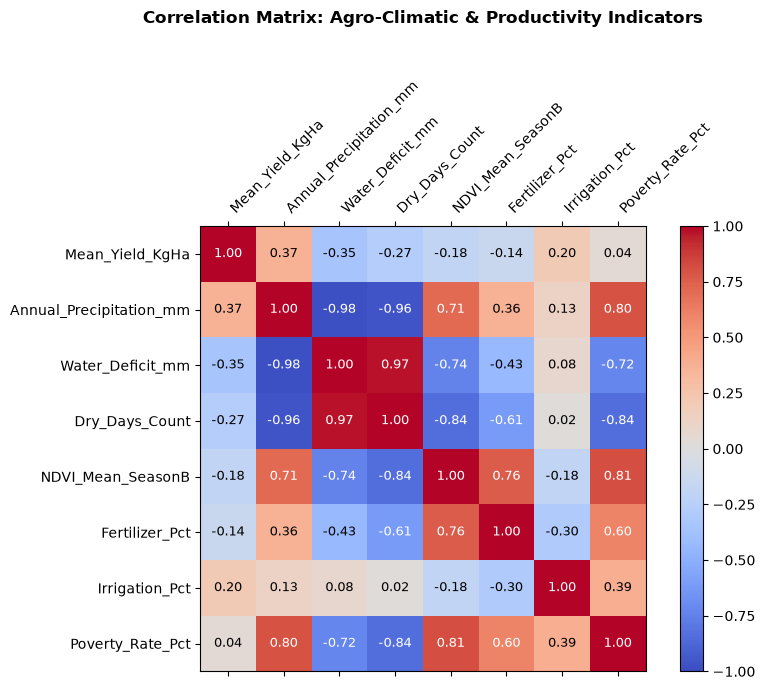

Correlation plot saved: ../data\plot_agro_climatic_correlation.png


In [11]:
# Correlation matrix of numeric agro-climatic indicators
num_cols = ['Mean_Yield_KgHa', 'Annual_Precipitation_mm', 'Water_Deficit_mm', 'Dry_Days_Count',
            'NDVI_Mean_SeasonB', 'Fertilizer_Pct', 'Irrigation_Pct', 'Poverty_Rate_Pct']
corr = district_summary[num_cols].corr().round(2)

fig, ax = plt.subplots(figsize=(9, 7))
cax = ax.matshow(corr, cmap='coolwarm', vmin=-1, vmax=1)
fig.colorbar(cax)

ax.set_xticks(range(len(num_cols)))
ax.set_yticks(range(len(num_cols)))
ax.set_xticklabels(num_cols, rotation=45, ha='left', fontsize=10)
ax.set_yticklabels(num_cols, fontsize=10)
ax.set_title('Correlation Matrix: Agro-Climatic & Productivity Indicators', fontsize=12, fontweight='bold', pad=40)

for i in range(len(num_cols)):
    for j in range(len(num_cols)):
        val = corr.iloc[i, j]
        ax.text(j, i, f'{val:.2f}', ha='center', va='center',
                color='white' if abs(val) > 0.5 else 'black', fontsize=9)

fig.tight_layout()
plot_corr_path = os.path.join(DATA_DIR, 'plot_agro_climatic_correlation.png')
plt.savefig(plot_corr_path, dpi=150, bbox_inches='tight')
plt.show()
print(f'Correlation plot saved: {plot_corr_path}')

---
## Phase 3 Completion & Key Takeaways

### 1. Satellite Remote Sensing & Agro-Climatic Insights:
- **Highland Greenness & Moisture Surplus:** `RUSIZI` exhibits the highest Sentinel-2 NDVI (Season A: 0.709, Season B: 0.714) and rainfall (1,522 mm, water deficit: 9.58 mm), consistent with tropical rainforest and humid tea belts. `MUSANZE` and `BURERA` demonstrate strong seasonal surges in NDVI during Season B (reaching 0.644 and 0.620 respectively), perfectly tracking peak vegetative canopy of Irish potato and cereal harvests.
- **Eastern Lowland Moisture Deficit:** `GATSIBO` suffers from intense water deficit (916.75 mm, 221 dry days), with NDVI falling from 0.548 in Season A down to 0.503 in Season B as soil moisture is depleted.

### 2. Deliverables Summary:
1. `notebooks/02_weather_and_gee_pipelines.ipynb`: Fully documented and executed pipeline utilizing real Google Earth Engine Sentinel-2 imagery.
2. `data/rwanda_district_weather_2024.csv`: 2,196 daily observations across 6 districts.
3. `data/rwanda_district_ndvi_2024.csv`: Real Sentinel-2 Season A and Season B mean vegetation indices.
4. `data/df_master_phase3.csv`: 36 master rows $\times$ 20 features, completely merged with zero missing values.